In [1]:
!pip install PyMPDATA

In [2]:
import PyMPDATA as mp
import numpy as np
import matplotlib.pyplot as plt

In [3]:
print(mp.__file__)

/usr/local/lib/python3.13/dist-packages/PyMPDATA/__init__.py


In [4]:
from PyMPDATA import ScalarField, VectorField, Options, boundary_conditions as bc, Stepper, Solver

options = Options(n_iters=4, infinite_gauge=True, nonoscillatory=True, third_order_terms=True)
common = {
    'halo': options.n_halo,
    'boundary_conditions': (bc.Periodic(),)
}

Psi = ScalarField(**common, data=(np.exp(-( x:=np.linspace(-2,8,40) )**2)))
C = VectorField(**common, data=(np.full(x.size+1, 1/4), ))

PsiStarting = Psi.get().copy()

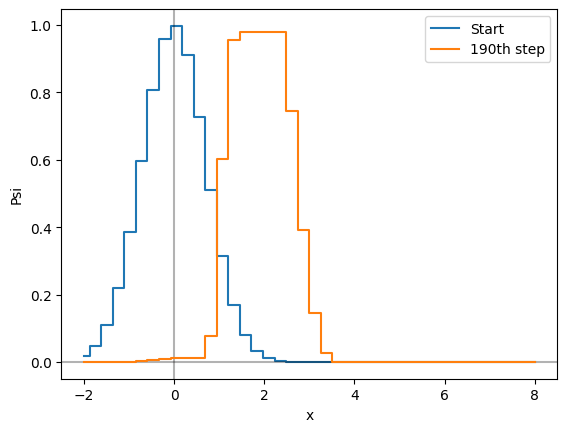

In [5]:

plt.step(x, PsiStarting, where='mid', label='Start')
plt.axhline(0, color='k', alpha=0.3)
plt.axvline(0, color='k', alpha=0.3)
plt.xlabel('x')
plt.ylabel('Psi')

solver = Solver(advector=C, advectee=Psi, stepper=Stepper(n_dims=1,options=options))
solver.advance(step:=190)

plt.step(x, Psi.get(), where='mid', label=f'{step}th step')
plt.legend()
plt.show()